In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import collections
import os
import time
import json
import random
import numpy as np

from PIL import Image

In [2]:
devices = tf.config.experimental.list_physical_devices("GPU")
for device in devices:
    tf.config.experimental.set_memory_growth(device, enable=True)

In [3]:
annotation_folder = r"C:\Users\KIIT\Downloads\Flickr8k_text"
image_folder = r"C:\Users\KIIT\Downloads\Flickr8k_Dataset"

In [4]:
annotation_file = os.path.join(annotation_folder, "Flickr8k.token.txt")
with open(annotation_file, "r", encoding="utf-8") as file:
    annotations = file.read()
    file.close()
annotations.split("\n")[0]

'1000268201_693b08cb0e.jpg#0\tA child in a pink dress is climbing up a set of stairs in an entry way .'

In [5]:
image_path_to_caption = collections.defaultdict(list)

for line in annotations.split('\n'):
    image_name = line.split("#")[0]
    caption = line.split("\t")[-1]
    caption = f"<start> {caption} <end>"
    image_path = os.path.join(image_folder, image_name)
    if image_path.endswith(".jpg"):
        image_path_to_caption[image_path].append(caption)

In [6]:
image_path_to_caption[os.path.join(image_folder, "1000268201_693b08cb0e.jpg")]

['<start> A child in a pink dress is climbing up a set of stairs in an entry way . <end>',
 '<start> A girl going into a wooden building . <end>',
 '<start> A little girl climbing into a wooden playhouse . <end>',
 '<start> A little girl climbing the stairs to her playhouse . <end>',
 '<start> A little girl in a pink dress going into a wooden cabin . <end>']

In [7]:
train_image_paths = list(image_path_to_caption.keys())
random.shuffle(train_image_paths)
print(len(train_image_paths))

8091


In [8]:
train_captions = []
image_name_vector = []

for image_path in train_image_paths:
    caption_list = image_path_to_caption[image_path]
    train_captions.extend(caption_list)
    image_name_vector.extend([image_path] * len(caption_list))

In [9]:
print(train_captions[0])

<start> A child jumps into a pool as a man looks on . <end>


<start> A girl with swimmies on is jumping into a pool . <end>


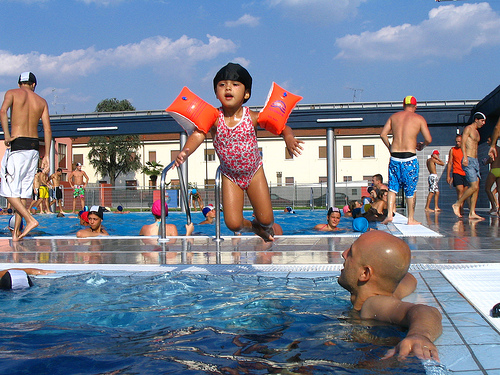

In [10]:
import os
from PIL import Image
from IPython.display import display

train_captions = []
image_name_vector = []

# Find the Flickr8k dataset folder
downloads = os.path.expanduser("~/Downloads")
image_files = {}

for root, dirs, files in os.walk(downloads):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files[file] = os.path.join(root, file)

# Match captions with their actual image paths
for image_path in train_image_paths:
    caption_list = image_path_to_caption[image_path]
    train_captions.extend(caption_list)

    filename = os.path.basename(image_path)
    actual_path = image_files.get(filename, image_path)

    image_name_vector.extend([actual_path] * len(caption_list))

# Print caption
print(train_captions[1])

# Display corresponding image
display(Image.open(image_name_vector[1]))

In [11]:
def load_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (299, 299))
    image = tf.keras.applications.inception_v3.preprocess_input(image)
    return image, image_path

In [12]:
image_model = tf.keras.applications.InceptionV3(include_top=False, weights='imagenet')
new_input = image_model.input
hidden_layer = image_model.layers[-1].output

image_features_extract_model = tf.keras.Model(new_input, hidden_layer)

In [13]:
encode_train = sorted(set(image_name_vector))

image_dataset = tf.data.Dataset.from_tensor_slices(encode_train)
image_dataset = image_dataset.map(load_image).batch(32)

In [14]:
from tqdm import tqdm
for img, path in tqdm(image_dataset):
    batch_features = image_features_extract_model(img)
    batch_features = tf.reshape(batch_features, (batch_features.shape[0], -1, batch_features.shape[3]))
    for bf, p in zip(batch_features, path):
        path_of_features = p.numpy().decode("utf-8")
        np.save(path_of_features, bf.numpy())

100%|████████████████████████████████████████████████████████████████████████████████| 253/253 [10:53<00:00,  2.58s/it]


In [15]:
def calc_max_length(tensor):
    return max(len(t) for t in tensor)

In [16]:
top_k = 5000

tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words=top_k,
    oov_token="<unk>",
    filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~ '
)

tokenizer.fit_on_texts(train_captions)

print("Start ID:", tokenizer.word_index.get("<start>"))
print("End ID:", tokenizer.word_index.get("<end>"))

Start ID: 3
End ID: 4


In [17]:
tokenizer.word_index['<pad>'] = 0
tokenizer.index_word[0] = '<pad>'

In [18]:
train_seqs = tokenizer.texts_to_sequences(train_captions)

In [19]:
cap_vector = tf.keras.preprocessing.sequence.pad_sequences(train_seqs, padding = "post")

In [20]:
max_length = calc_max_length(train_seqs)
max_length

39

In [21]:
img_to_cap_vector = collections.defaultdict(list)
for img, cap in zip(image_name_vector, cap_vector):
    img_to_cap_vector[img].append(cap)

In [22]:
img_keys = list(img_to_cap_vector.keys())
random.shuffle(img_keys)
slice_index = int(len(img_keys)*0.8)
img_name_train_keys, img_name_val_keys = img_keys[:slice_index], img_keys[slice_index:]

In [23]:
img_name_train_keys[1]

'C:\\Users\\KIIT/Downloads\\Flickr8k_Dataset\\Flicker8k_Dataset\\2744600462_5804577296.jpg'

In [24]:
img_name_train = []
cap_train = []
for imgt in img_name_train_keys:
    capt_len = len(img_to_cap_vector[imgt])
    img_name_train.extend([imgt] * capt_len)
    cap_train.extend(img_to_cap_vector[imgt])

In [25]:
img_name_val, cap_val = [], []
for imgv in img_name_val_keys:
    capv_len = len(img_to_cap_vector[imgv])
    img_name_val.extend([imgv] * capv_len)
    cap_val.extend(img_to_cap_vector[imgv])

In [26]:
len(img_name_train), len(cap_train), len(img_name_val), len(cap_val)

(32360, 32360, 8095, 8095)

In [27]:
batch_size = 16
buffer_size = 500
embedding_dim = 256
units = 512
vocab_size = top_k + 1
num_steps = len(img_name_train)
features_shape = 2048
attention_features_shape = 64

In [28]:
def map_func(image_name, cap):
    img_tensor = np.load(image_name.decode("utf-8") + ".npy")
    return img_tensor, cap

In [29]:
dataset = tf.data.Dataset.from_tensor_slices((img_name_train, cap_train))

In [30]:
dataset = dataset.map(lambda item1, item2: tf.numpy_function(
    map_func, [item1, item2], [tf.float32, tf.int32]))

In [31]:
dataset = dataset.shuffle(buffer_size).batch(batch_size)

In [32]:
class BahdanauAttention(tf.keras.Model):
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)
        
    def call(self, features, hidden):
        hidden_with_time_axis = tf.expand_dims(hidden, 1)
        attention_hidden_layer = (tf.nn.tanh(self.W1(features) + 
                                             self.W2(hidden_with_time_axis)))
        
        score = self.V(attention_hidden_layer)
        attention_weights = tf.nn.softmax(score, axis=1)
        context_vector = attention_weights * features
        context_vector = tf.reduce_sum(context_vector, axis=1)
        return context_vector, attention_weights

In [33]:
class CNN_Encoder(tf.keras.Model):
    def __init__(self, embedding_dim):
        super(CNN_Encoder, self).__init__()
        self.fc = tf.keras.layers.Dense(embedding_dim)
        
    def call(self, x):
        x = self.fc(x)
        x = tf.nn.relu(x)
        return x

In [34]:
class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size):
        super(RNN_Decoder, self).__init__()
        self.units = units
        
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(self.units,
                                       return_sequences=True,
                                       return_state=True,
                                       recurrent_initializer='glorot_uniform')
        self.fc1 = tf.keras.layers.Dense(self.units)
        self.fc2 = tf.keras.layers.Dense(vocab_size)
        
        self.attention = BahdanauAttention(self.units)
        
    def call(self, x, features, hidden):
        context_vector, attention_weights = self.attention(features, hidden)
        
        x = self.embedding(x)
        
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)
        
        output, state = self.gru(x,initial_state=hidden)
        
        x = self.fc1(output)
        
        x = tf.reshape(x, (-1, x.shape[2]))
        
        x = self.fc2(x)
        
        return x, state, attention_weights
        
    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))

In [35]:
encoder = CNN_Encoder(embedding_dim)
decoder = RNN_Decoder(embedding_dim, units, vocab_size)

In [36]:
optimizer = tf.keras.optimizers.Adam()
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")

def loss_function(real, pred):
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    loss_ = loss_object(real, pred)
    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask
    return tf.reduce_mean(loss_)

In [37]:
checkpoint_path = "./checkpoints/train"
ckpt = tf.train.Checkpoint(encoder=encoder, decoder=decoder, optimizer=optimizer)
ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint_path, max_to_keep=5)

In [38]:
start_epoch = 0
if ckpt_manager.latest_checkpoint:
    start_epoch = int(ckpt_manager.latest_checkpoint.split('-')[-1])
    ckpt.restore(ckpt_manager.latest_checkpoint)

In [39]:
loss_plot = []

In [40]:
@tf.function
def train_step(img_tensor, target):
    loss = 0
    hidden = decoder.reset_state(batch_size=target.shape[0])
    dec_input = tf.expand_dims([tokenizer.word_index["<start>"]] * target.shape[0], 1)
    
    with tf.GradientTape() as tape:
        features = encoder(img_tensor)
        for i in range(1, target.shape[1]):
            prediction, hidden, _ = decoder(dec_input, features, hidden)
            loss += loss_function(target[:, i], prediction)
            dec_input = tf.expand_dims(target[:, i], 1)
            
    total_loss = (loss / int(target.shape[1]))
    trainable_variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, trainable_variables)
    optimizer.apply_gradients(zip(gradients, trainable_variables))
    return loss, total_loss

In [43]:
print(train_step)

In [44]:
epochs = 20
for epoch in range(start_epoch, epochs):
    start = time.time()
    total_loss = 0
    
    for (batch, (img_tensor, target)) in enumerate(dataset):
        batch_loss, t_loss = train_step(img_tensor, target)
        total_loss += t_loss
        
        if batch % 100 == 0:
            average_batch_loss = batch_loss.numpy() / int(target.shape[1])
            print(f"Epoch {epoch + 1} Batch {batch} Loss {average_batch_loss:.4f}")
            
    loss_plot.append(total_loss / num_steps)
    
    if epoch % 5 == 0:
        ckpt_manager.save()
        
    print(f"Epoch {epoch + 1} Loss {total_loss / num_steps:.6f}")
    print(f"Time taken for 1 epoch {time.time() - start:.2f} sec\n")

Epoch 5 Batch 0 Loss 1.1486
Epoch 5 Batch 100 Loss 1.0903
Epoch 5 Batch 200 Loss 1.1083
Epoch 5 Batch 300 Loss 0.8054
Epoch 5 Batch 400 Loss 0.9004
Epoch 5 Batch 500 Loss 1.1008
Epoch 5 Batch 600 Loss 0.8730
Epoch 5 Batch 700 Loss 0.8583
Epoch 5 Batch 800 Loss 1.0513
Epoch 5 Batch 900 Loss 0.7731
Epoch 5 Batch 1000 Loss 0.8947
Epoch 5 Batch 1100 Loss 1.0432
Epoch 5 Batch 1200 Loss 0.9945
Epoch 5 Batch 1300 Loss 0.7870
Epoch 5 Batch 1400 Loss 0.9339
Epoch 5 Batch 1500 Loss 0.8358
Epoch 5 Batch 1600 Loss 1.1010
Epoch 5 Batch 1700 Loss 0.9465
Epoch 5 Batch 1800 Loss 0.9269
Epoch 5 Batch 1900 Loss 0.8497
Epoch 5 Batch 2000 Loss 0.9247
Epoch 5 Loss 0.061446
Time taken for 1 epoch 2163.09 sec

Epoch 6 Batch 0 Loss 1.1495
Epoch 6 Batch 100 Loss 0.8111
Epoch 6 Batch 200 Loss 0.9427
Epoch 6 Batch 300 Loss 0.8671
Epoch 6 Batch 400 Loss 0.9640
Epoch 6 Batch 500 Loss 0.6256
Epoch 6 Batch 600 Loss 0.7648
Epoch 6 Batch 700 Loss 0.8472
Epoch 6 Batch 800 Loss 0.8304
Epoch 6 Batch 900 Loss 1.0019
Epoch

In [45]:
def evaluate(image):
    attention_plot=np.zeros((max_length,64))
    hidden=decoder.reset_state(batch_size=1)
    temp_input=tf.expand_dims(load_image(image)[0],0)
    img_tensor_val=image_features_extract_model(temp_input)
    img_tensor_val=tf.reshape(img_tensor_val, (img_tensor_val.shape[0],-1,img_tensor_val.shape[3]))
    features=encoder(img_tensor_val)
    dec_input=tf.expand_dims([tokenizer.word_index['<start>']],0)
    result1=[]
    for i in range(max_length):
        predictions, hidden, attention_weights=decoder(dec_input, features, hidden)
        attention_plot[i]=tf.reshape(attention_weights, (-1,)).numpy()
        predicted_id=int(tf.argmax(predictions[0]).numpy())
        predicted_word=tokenizer.index_word.get(predicted_id)
        if predicted_word is None or predicted_word=='<end>':
            break
        result1.append(predicted_word)
    
        dec_input=tf.expand_dims([predicted_id],0)
    attention_plot=attention_plot[: len(result1)]
    return result1, attention_plot

In [46]:
def plot_attention(image, result, attention_plot):
    temp_image = np.array(Image.open(image))

    fig = plt.figure(figsize=(10, 10))

    len_result = len(result)
    for i in range(len_result):
        temp_att = np.resize(attention_plot[i], (8, 8))
        grid_size = max(int(np.ceil(len_result/2)), 2)
        ax = fig.add_subplot(grid_size, grid_size, i+1)
        ax.set_title(result[i])
        img = ax.imshow(temp_image)
        ax.imshow(temp_att, cmap='gray', alpha=0.6, extent=img.get_extent())
    plt.tight_layout()
    plt.show()

Real Caption: <start> the male kayaker is moving through the rough water <end>
Prediction Caption: a man in a red life vest is <unk> the boat in the water


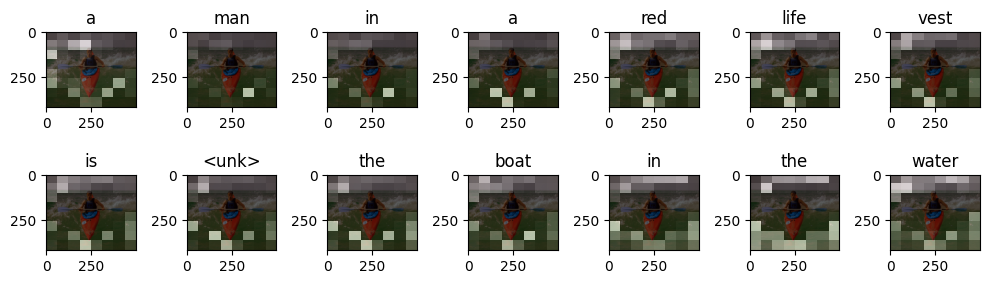

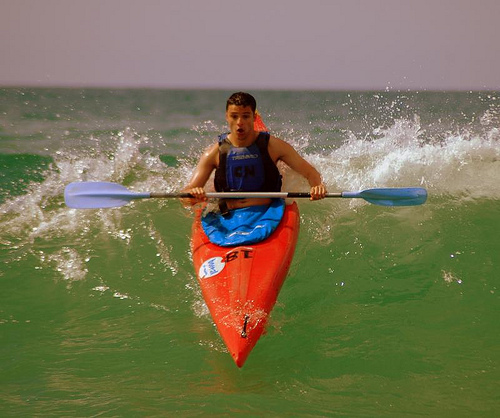

In [47]:
rid = np.random.randint(0, len(img_name_val))
image = img_name_val[rid]
real_caption = ' '.join([tokenizer.index_word[i] for i in cap_val[rid] if i not in [0]])
result1, attention_plot = evaluate(image)

print('Real Caption:', real_caption)
print('Prediction Caption:', ' '.join(result1))
plot_attention(image, result1, attention_plot)
# opening the image
Image.open(img_name_val[rid])

In [50]:
%pip install nltk


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
%pip install --upgrade pip

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----------------------- ---------------- 1.0/1.8 MB 12.5 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 9.9 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.1
    Uninstalling pip-26.2.1:
      Successfully uninstalled pip-26.2.1
Note: you may need to restart the kernel to use updated packages.



Image 1
Real caption      : a man in a white shirt and jeans playing an accordion
Predicted caption : a boy plays with a foam football on a gray haired child
Word precision    : 0.1667
Word recall       : 0.1818
Word F1-score     : 0.1739

Image 2
Real caption      : a man in white is playing a black accordion
Predicted caption : a boy plays with a foam football on a gray haired child
Word precision    : 0.1667
Word recall       : 0.2222
Word F1-score     : 0.1905

Image 3
Real caption      : a man plays an accordion on a park bench
Predicted caption : a boy plays with a foam football on a gray haired child
Word precision    : 0.3333
Word recall       : 0.4444
Word F1-score     : 0.381

Image 4
Real caption      : a man plays an accordion
Predicted caption : a boy plays with a foam football on a gray haired child
Word precision    : 0.1667
Word recall       : 0.4
Word F1-score     : 0.2353

Image 5
Real caption      : a seated boy plays the accordion
Predicted caption : a boy plays wi

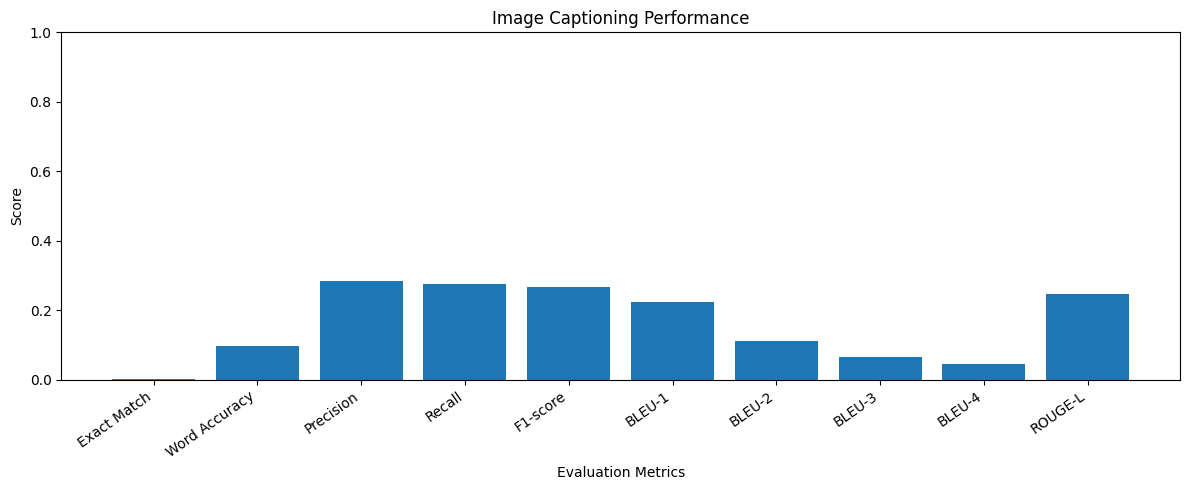

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
num_images = min(500, len(img_name_val))

start_id = tokenizer.word_index.get("<start>")
end_id = tokenizer.word_index.get("<end>")

smooth = SmoothingFunction().method1

def get_reference_caption(caption_ids):
    words = []

    for token in caption_ids:
        token = int(token)

        if token == 0 or token == start_id:
            continue

        if end_id is not None and token == end_id:
            break

        word = tokenizer.index_word.get(token)

        if word:
            words.append(word.lower())

    return words


def get_predicted_caption(image_path):
    result, attention_plot = evaluate(image_path)

    return [
        str(word).lower()
        for word in result
        if str(word).lower() not in
        ["<start>", "<end>", "<pad>", "<unk>"]
    ]


def caption_prf(reference, prediction):
    ref_counts = Counter(reference)
    pred_counts = Counter(prediction)

    matched = sum((ref_counts & pred_counts).values())

    precision = matched / len(prediction) if prediction else 0.0
    recall = matched / len(reference) if reference else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    return precision, recall, f1

def rouge_l(reference, prediction):
    m, n = len(reference), len(prediction)

    if m == 0 or n == 0:
        return 0.0

    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if reference[i - 1] == prediction[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])

    lcs = dp[m][n]

    p = lcs / n
    r = lcs / m

    return 2 * p * r / (p + r) if p + r > 0 else 0.0

bleu1_scores = []
bleu2_scores = []
bleu3_scores = []
bleu4_scores = []

precision_scores = []
recall_scores = []
f1_scores = []
rouge_scores = []
exact_matches = []

word_correct = 0
word_total = 0

all_predictions = []
all_references = []

for idx in range(num_images):

    image_path = img_name_val[idx]

    if isinstance(image_path, bytes):
        image_path = image_path.decode("utf-8")

    reference = get_reference_caption(cap_val[idx])
    prediction = get_predicted_caption(image_path)

    all_references.append(reference)
    all_predictions.append(prediction)

   
    exact_matches.append(int(reference == prediction))

    max_len = max(len(reference), len(prediction))

    for pos in range(max_len):
        true_word = (
            reference[pos] if pos < len(reference) else "<missing>"
        )
        pred_word = (
            prediction[pos] if pos < len(prediction) else "<missing>"
        )

        word_total += 1

        if true_word == pred_word:
            word_correct += 1

    p, r, f = caption_prf(reference, prediction)

    precision_scores.append(p)
    recall_scores.append(r)
    f1_scores.append(f)

    bleu1_scores.append(sentence_bleu(
        [reference], prediction,
        weights=(1, 0, 0, 0),
        smoothing_function=smooth
    ))

    bleu2_scores.append(sentence_bleu(
        [reference], prediction,
        weights=(0.5, 0.5, 0, 0),
        smoothing_function=smooth
    ))

    bleu3_scores.append(sentence_bleu(
        [reference], prediction,
        weights=(1/3, 1/3, 1/3, 0),
        smoothing_function=smooth
    ))

    bleu4_scores.append(sentence_bleu(
        [reference], prediction,
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smooth
    ))

    rouge_scores.append(rouge_l(reference, prediction))

    if idx < 5:
        print(f"\nImage {idx + 1}")
        print("Real caption      :", " ".join(reference))
        print("Predicted caption :", " ".join(prediction))
        print("Word precision    :", round(p, 4))
        print("Word recall       :", round(r, 4))
        print("Word F1-score     :", round(f, 4))

def mean_score(values):
    return float(np.mean(values)) if len(values) else 0.0


exact_accuracy = mean_score(exact_matches)

word_accuracy = (
    word_correct / word_total if word_total > 0 else 0.0
)

precision = mean_score(precision_scores)
recall = mean_score(recall_scores)
f1 = mean_score(f1_scores)

bleu1 = mean_score(bleu1_scores)
bleu2 = mean_score(bleu2_scores)
bleu3 = mean_score(bleu3_scores)
bleu4 = mean_score(bleu4_scores)

rouge = mean_score(rouge_scores)

print("\n" + "=" * 50)
print("       IMAGE CAPTIONING EVALUATION")
print("=" * 50)

print("Images evaluated       :", num_images)
print(f"Exact-match accuracy   : {exact_accuracy:.4f} ({exact_accuracy*100:.2f}%)")
print(f"Word-level accuracy    : {word_accuracy:.4f} ({word_accuracy*100:.2f}%)")
print(f"Word precision         : {precision:.4f}")
print(f"Word recall            : {recall:.4f}")
print(f"Word F1-score          : {f1:.4f}")
print(f"BLEU-1                 : {bleu1:.4f}")
print(f"BLEU-2                 : {bleu2:.4f}")
print(f"BLEU-3                 : {bleu3:.4f}")
print(f"BLEU-4                 : {bleu4:.4f}")
print(f"ROUGE-L                : {rouge:.4f}")

try:
    from nltk.translate.meteor_score import meteor_score

    meteor_scores = [
        meteor_score([reference], prediction)
        for reference, prediction
        in zip(all_references, all_predictions)
    ]

    meteor = mean_score(meteor_scores)
    print(f"METEOR                 : {meteor:.4f}")

except Exception as e:
    print("METEOR unavailable:", e)


metric_names = [
    "Exact Match", "Word Accuracy", "Precision", "Recall",
    "F1-score", "BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4",
    "ROUGE-L"
]

metric_values = [
    exact_accuracy, word_accuracy, precision, recall, f1,
    bleu1, bleu2, bleu3, bleu4, rouge
]

plt.figure(figsize=(12, 5))
plt.bar(metric_names, metric_values)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("Image Captioning Performance")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [56]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\KIIT\AppData\Roaming\nltk_data...


True

In [57]:
import numpy as np
import re
from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

smooth = SmoothingFunction().method1


def decode_reference_caption(caption):
    """
    Convert a padded token-ID sequence into readable text.
    Remove start, end and padding tokens.
    """
    words = []

    for token in caption:
        token = int(token)

        if token == 0:
            continue

        word = tokenizer.index_word.get(token, "<unk>")

        if word == "<start>":
            continue

        if word == "<end>":
            break

        if word != "<pad>":
            words.append(word)

    return words


def clean_words(words):
    """Normalize words for BLEU comparison."""
    cleaned = []

    for word in words:
        word = str(word).lower().strip()
        word = re.sub(r"[^a-z0-9'-]", "", word)

        if word and word not in ["<start>", "<end>", "<pad>"]:
            cleaned.append(word)

    return cleaned


def get_references(image_path):
    """
    Find the validation image and decode its stored caption.
    This assumes cap_val contains one caption sequence per
    entry in img_name_val.
    """
    target = str(image_path).replace("\\", "/").lower()

    matching_indices = [
        i for i, path in enumerate(img_name_val)
        if str(path).replace("\\", "/").lower() == target
    ]

    references = []

    for idx in matching_indices:
        words = decode_reference_caption(cap_val[idx])
        words = clean_words(words)

        if words:
            references.append(words)

    return references


def evaluate_caption_quality(image_path):
    """
    Generate a caption, compare it with available references,
    calculate BLEU scores and assign an assessment.
    """

    predicted_words, attention_plot = evaluate(image_path)

    predicted_words = clean_words(predicted_words)

    references = get_references(image_path)

    if not references:
        return {
            "image": str(image_path),
            "generated_caption": " ".join(predicted_words),
            "reference_captions": "No matching reference found",
            "BLEU-1": None,
            "BLEU-2": None,
            "assessment": "Needs Review"
        }

    bleu1_scores = [
        sentence_bleu(
            [ref],
            predicted_words,
            weights=(1, 0, 0, 0),
            smoothing_function=smooth
        )
        for ref in references
    ]

    bleu2_scores = [
        sentence_bleu(
            [ref],
            predicted_words,
            weights=(0.5, 0.5, 0, 0),
            smoothing_function=smooth
        )
        for ref in references
    ]

    best_bleu1 = max(bleu1_scores, default=0.0)
    best_bleu2 = max(bleu2_scores, default=0.0)

    if best_bleu1 >= 0.60 and best_bleu2 >= 0.30:
        assessment = "Likely Correct"

    elif best_bleu1 >= 0.30 or best_bleu2 >= 0.15:
        assessment = "Partially Correct"

    else:
        assessment = "Needs Review"

    return {
        "image": str(image_path),
        "generated_caption": " ".join(predicted_words),
        "reference_captions": " | ".join(
            " ".join(ref) for ref in references
        ),
        "BLEU-1": round(best_bleu1, 3),
        "BLEU-2": round(best_bleu2, 3),
        "assessment": assessment
    }

num_images_to_test = min(20, len(img_name_val))

results = []

for i in range(num_images_to_test):
    image_path = img_name_val[i]

    try:
        result = evaluate_caption_quality(image_path)
        results.append(result)

        print("\nImage:", result["image"])
        print("Generated:", result["generated_caption"])
        print("Reference:", result["reference_captions"])
        print("BLEU-1:", result["BLEU-1"])
        print("BLEU-2:", result["BLEU-2"])
        print("Assessment:", result["assessment"])

    except Exception as e:
        print("\nError processing:", image_path)
        print("Reason:", str(e))


if results:
    import pandas as pd

    results_df = pd.DataFrame(results)

    print("\n" + "=" * 60)
    print("EVALUATION SUMMARY")
    print("=" * 60)

    print("\nTotal images processed:", len(results_df))

    print("\nAssessment counts:")
    print(results_df["assessment"].value_counts())

    print("\nAverage BLEU scores:")
    print("BLEU-1:", results_df["BLEU-1"].mean())
    print("BLEU-2:", results_df["BLEU-2"].mean())

    display(results_df)

    results_df.to_csv(
        "image_caption_evaluation.csv",
        index=False
    )

    print("\nResults saved to image_caption_evaluation.csv")

else:
    print("No images were evaluated successfully.")


Image: C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flicker8k_Dataset\300148649_72f7f0399c.jpg
Generated: a boy plays with a foam football on a gray haired child
Reference: a man in a white shirt and jeans playing an accordion | a man in white is playing a black accordion | a man plays an accordion on a park bench | a man plays an accordion | a seated boy plays the accordion
BLEU-1: 0.333
BLEU-2: 0.174
Assessment: Partially Correct

Image: C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flicker8k_Dataset\300148649_72f7f0399c.jpg
Generated: a boy plays with a foam football on a gray haired child
Reference: a man in a white shirt and jeans playing an accordion | a man in white is playing a black accordion | a man plays an accordion on a park bench | a man plays an accordion | a seated boy plays the accordion
BLEU-1: 0.333
BLEU-2: 0.174
Assessment: Partially Correct

Image: C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flicker8k_Dataset\300148649_72f7f0399c.jpg
Generated: a boy plays with a foam footbal

,image,generated_caption,reference_captions,BLEU-1,BLEU-2,assessment
0,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
1,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
2,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
3,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
4,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
5,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
6,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
7,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
8,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
9,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review



Results saved to image_caption_evaluation.csv


In [58]:
idx = 0

prediction, attention_plot = evaluate(img_name_val[idx])

print("Generated output:", prediction)
print("Output type:", type(prediction))

print("\nReference caption:")
print(cap_val[idx])

print("\nImage path:")
print(img_name_val[idx])

Generated output: ['a', 'boy', 'plays', 'with', 'a', 'foam', 'football', 'on', 'a', 'gray', 'haired', 'child']
Output type: <class 'list'>

Reference caption:
[   3    2   12    5    2   15   37    9  233   35   29 1915    4    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0]

Image path:
C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flicker8k_Dataset\300148649_72f7f0399c.jpg


In [59]:
def decode_reference_caption(token_ids):
    words = []

    for token_id in np.array(token_ids).flatten():
        token_id = int(token_id)

        if token_id == 0:
            continue

        word = tokenizer.index_word.get(token_id)

        if word is not None and word not in ["<start>", "<end>", "<pad>"]:
            words.append(word)

    return " ".join(words)
idx = 0

print("Generated caption:")
print(" ".join(evaluate(img_name_val[idx])[0]))

print("\nDecoded reference caption:")
print(decode_reference_caption(cap_val[idx]))

Generated caption:
a boy plays with a foam football on a gray haired child

Decoded reference caption:
a man in a white shirt and jeans playing an accordion


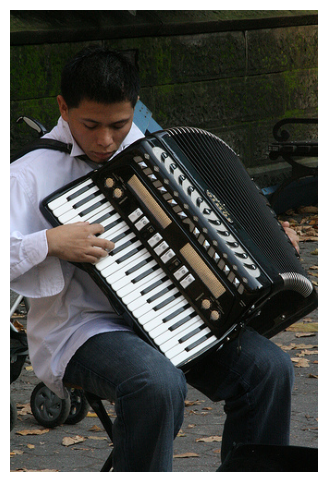

Generated caption:
a boy plays with a foam football on a gray haired child

Reference caption:
a man in a white shirt and jeans playing an accordion


In [60]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 0

img = Image.open(img_name_val[idx])
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

print("Generated caption:")
print(" ".join(evaluate(img_name_val[idx])[0]))

print("\nReference caption:")
print(decode_reference_caption(cap_val[idx]))

In [61]:
print("attention_features_shape =", attention_features_shape)
sample_image = img_name_val[0]
temp_input = tf.expand_dims(load_image(sample_image)[0], 0)

img_tensor_val = image_features_extract_model(temp_input)

print("CNN output shape:", img_tensor_val.shape)

img_tensor_val = tf.reshape(
    img_tensor_val,
    (img_tensor_val.shape[0], -1, img_tensor_val.shape[3])
)

print("Reshaped features:", img_tensor_val.shape)

features = encoder(img_tensor_val)
print("Encoder features:", features.shape)

hidden = decoder.reset_state(batch_size=1)
dec_input = tf.expand_dims([tokenizer.word_index['<start>']], 0)

predictions, hidden, attention_weights = decoder(
    dec_input, features, hidden
)

print("Actual attention weights shape:", attention_weights.shape)

attention_features_shape = 64
CNN output shape: (1, 8, 8, 2048)
Reshaped features: (1, 64, 2048)
Encoder features: (1, 64, 256)
Actual attention weights shape: (1, 64, 1)


Number of saved loss values: 16


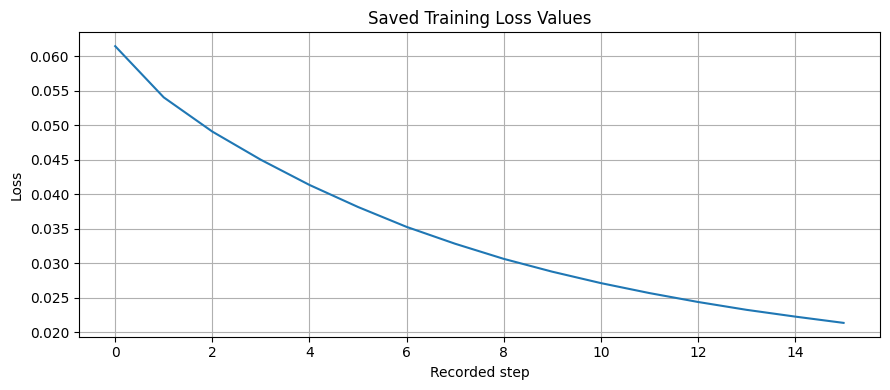

First loss: 0.06144557148218155
Last loss: 0.021342400461435318


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

loss_values = []

for value in loss_plot:
    try:
        loss_values.append(float(value.numpy()))
    except (AttributeError, TypeError, ValueError):
        try:
            loss_values.append(float(value))
        except (TypeError, ValueError):
            continue

print("Number of saved loss values:", len(loss_values))

if loss_values:
    plt.figure(figsize=(9, 4))
    plt.plot(loss_values)
    plt.title("Saved Training Loss Values")
    plt.xlabel("Recorded step")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("First loss:", loss_values[0])
    print("Last loss:", loss_values[-1])
else:
    print("No numeric loss values could be extracted.")

In [63]:
print("Total images:", len(results_df))

print("\nAssessment counts:")
print(results_df["assessment"].value_counts())

print("\nBLEU-1 statistics:")
print(results_df["BLEU-1"].describe())

print("\nBLEU-2 statistics:")
print(results_df["BLEU-2"].describe())

print("\nFirst 10 evaluated captions:")
display(
    results_df[
        [
            "generated_caption",
            "reference_captions",
            "BLEU-1",
            "BLEU-2",
            "assessment"
        ]
    ].head(10)
)

Total images: 20

Assessment counts:
assessment
Partially Correct    10
Needs Review         10
Name: count, dtype: int64

BLEU-1 statistics:
count    20.000000
mean      0.203500
std       0.126804
min       0.000000
25%       0.173250
50%       0.240500
75%       0.270750
max       0.333000
Name: BLEU-1, dtype: float64

BLEU-2 statistics:
count    20.000000
mean      0.105250
std       0.068792
min       0.000000
25%       0.072000
50%       0.123500
75%       0.156750
max       0.174000
Name: BLEU-2, dtype: float64

First 10 evaluated captions:


,generated_caption,reference_captions,BLEU-1,BLEU-2,assessment
0,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
1,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
2,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
3,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
4,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.333,0.174,Partially Correct
5,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
6,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
7,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
8,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
9,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review


In [64]:
from collections import Counter

paths = [
    str(p).replace("\\", "/").lower()
    for p in img_name_val
]

counts = Counter(paths)

print("Total validation entries:", len(paths))
print("Unique image paths:", len(set(paths)))
print("Paths appearing more than once:",
      sum(1 for count in counts.values() if count > 1))

print("\nExample duplicate paths:")
for path, count in counts.items():
    if count > 1:
        print(path, "appears", count, "times")
        break

Total validation entries: 8095
Unique image paths: 1619
Paths appearing more than once: 1619

Example duplicate paths:
c:/users/kiit/downloads/flickr8k_dataset/flicker8k_dataset/300148649_72f7f0399c.jpg appears 5 times


In [65]:
import numpy as np
import pandas as pd
import re
from collections import defaultdict
from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

smooth = SmoothingFunction().method1

def decode_reference_caption(caption):
    words = []

    for token in caption:
        token = int(token)

        if token == 0:
            continue

        word = tokenizer.index_word.get(token, "<unk>")

        if word == "<start>":
            continue

        if word == "<end>":
            break

        if word != "<pad>":
            words.append(word)

    return words


def clean_words(words):
    cleaned = []

    for word in words:
        word = str(word).lower().strip()
        word = re.sub(r"[^a-z0-9'-]", "", word)

        if word and word not in ("<start>", "<end>", "<pad>"):
            cleaned.append(word)

    return cleaned


image_references = defaultdict(list)
image_paths = {}

for image_path, caption in zip(img_name_val, cap_val):

    normalized_path = str(image_path).replace("\\", "/").lower()

    image_paths.setdefault(normalized_path, image_path)

    reference = clean_words(decode_reference_caption(caption))

    if reference:
        image_references[normalized_path].append(reference)


print("Unique validation images:", len(image_paths))


results = []

for count, (normalized_path, image_path) in enumerate(
    image_paths.items(), start=1
):
    try:
        predicted_words, _ = evaluate(image_path)
        predicted_words = clean_words(predicted_words)

        references = image_references[normalized_path]

        if not predicted_words or not references:
            assessment = "Needs Review"
            best_bleu1 = 0.0
            best_bleu2 = 0.0

        else:
            bleu1 = sentence_bleu(
                references,
                predicted_words,
                weights=(1, 0, 0, 0),
                smoothing_function=smooth
            )

            bleu2 = sentence_bleu(
                references,
                predicted_words,
                weights=(0.5, 0.5, 0, 0),
                smoothing_function=smooth
            )

            best_bleu1 = bleu1
            best_bleu2 = bleu2

            if best_bleu1 >= 0.60 and best_bleu2 >= 0.30:
                assessment = "Likely Correct"
            elif best_bleu1 >= 0.30 or best_bleu2 >= 0.15:
                assessment = "Partially Correct"
            else:
                assessment = "Needs Review"

        results.append({
            "image": str(image_path),
            "generated_caption": " ".join(predicted_words),
            "reference_captions": " | ".join(
                " ".join(ref) for ref in references
            ),
            "BLEU-1": round(best_bleu1, 3),
            "BLEU-2": round(best_bleu2, 3),
            "assessment": assessment
        })

        if count % 100 == 0:
            print(f"Evaluated {count}/{len(image_paths)} images")

    except Exception as e:
        print("Error:", image_path, str(e))

results_df = pd.DataFrame(results)

print("\nTotal unique images evaluated:", len(results_df))

print("\nAssessment counts:")
print(results_df["assessment"].value_counts())

print("\nAverage BLEU scores:")
print(results_df[["BLEU-1", "BLEU-2"]].mean())

display(results_df.head(20))

results_df.to_csv(
    "image_caption_evaluation_unique_images.csv",
    index=False
)

print("\nSaved: image_caption_evaluation_unique_images.csv")

Unique validation images: 1619
Evaluated 100/1619 images
Evaluated 200/1619 images
Evaluated 300/1619 images
Evaluated 400/1619 images
Evaluated 500/1619 images
Evaluated 600/1619 images
Evaluated 700/1619 images
Evaluated 800/1619 images
Evaluated 900/1619 images
Evaluated 1000/1619 images
Evaluated 1100/1619 images
Evaluated 1200/1619 images
Evaluated 1300/1619 images
Evaluated 1400/1619 images
Evaluated 1500/1619 images
Evaluated 1600/1619 images

Total unique images evaluated: 1619

Assessment counts:
assessment
Partially Correct    1012
Likely Correct        364
Needs Review          243
Name: count, dtype: int64

Average BLEU scores:
BLEU-1    0.474889
BLEU-2    0.283277
dtype: float64


,image,generated_caption,reference_captions,BLEU-1,BLEU-2,assessment
0,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a boy plays with a foam football on a gray hai...,a man in a white shirt and jeans playing an ac...,0.417,0.275,Partially Correct
1,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,two boys talk to each other,a little girl in pajamas runs down a hall with...,0.000,0.000,Needs Review
2,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,two children in a yard with a metal box in the...,a little girl laughs while playing in a play h...,0.333,0.174,Partially Correct
3,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a woman wearing a pink tank top standing on a ...,a man in a red jacket is standing at the top o...,0.308,0.111,Partially Correct
4,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a man in a green t shirt is skateboarding on a...,a blonde boy stands among people in a shady se...,0.583,0.399,Partially Correct
5,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a group of children are playing on a wooden bench,a girl sits with unk tools examining a rock | ...,0.200,0.047,Needs Review
6,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a man walking down the street,a lone person wearing a quilt walking along th...,0.667,0.115,Partially Correct
7,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a dog is running through the snow,a dog runs through snow in front of the woods ...,1.000,1.000,Likely Correct
8,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a girl in a green dress and is holding a sign ...,a woman in gray is smoking a cigarette | a wom...,0.467,0.183,Partially Correct
9,C:\Users\KIIT/Downloads\Flickr8k_Dataset\Flick...,a group of people pose together,a group of unk men and women standing in a lin...,0.342,0.265,Partially Correct



Saved: image_caption_evaluation_unique_images.csv


Image folder found: C:\Users\KIIT\Downloads\Flickr8k_Dataset\Flicker8k_Dataset

Total validation entries: 8095
Unique images with references: 1619
Duplicate captions removed: 6
Evaluated 100 of 1619 images
Evaluated 200 of 1619 images
Evaluated 300 of 1619 images
Evaluated 400 of 1619 images
Evaluated 500 of 1619 images
Evaluated 600 of 1619 images
Evaluated 700 of 1619 images
Evaluated 800 of 1619 images
Evaluated 900 of 1619 images
Evaluated 1000 of 1619 images
Evaluated 1100 of 1619 images
Evaluated 1200 of 1619 images
Evaluated 1300 of 1619 images
Evaluated 1400 of 1619 images
Evaluated 1500 of 1619 images
Evaluated 1600 of 1619 images

Evaluation completed.
Images evaluated: 1619

SAMPLE CAPTION CHECK

Image: 300148649_72f7f0399c.jpg
Generated: 'a boy plays with a foam football on a gray haired child'
References:
 - a man in a white shirt and jeans playing an accordion
 - a man in white is playing a black accordion
 - a man plays an accordion on a park bench
 - a man plays an acco

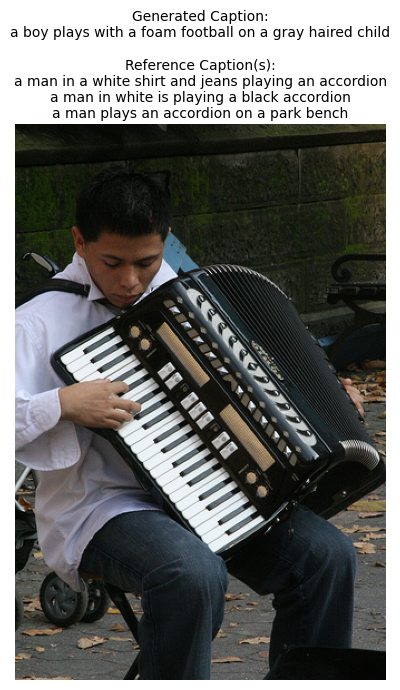

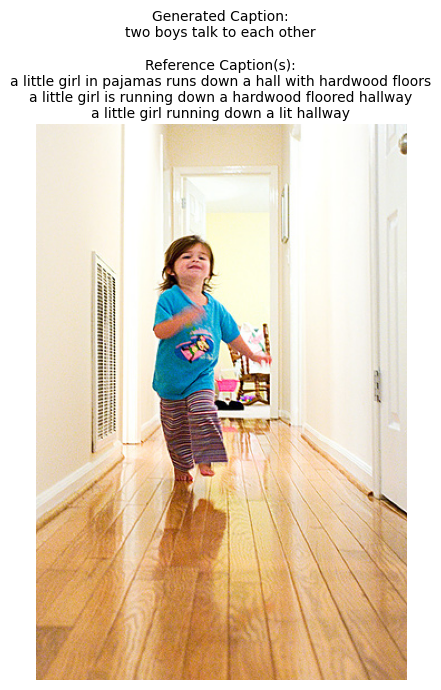

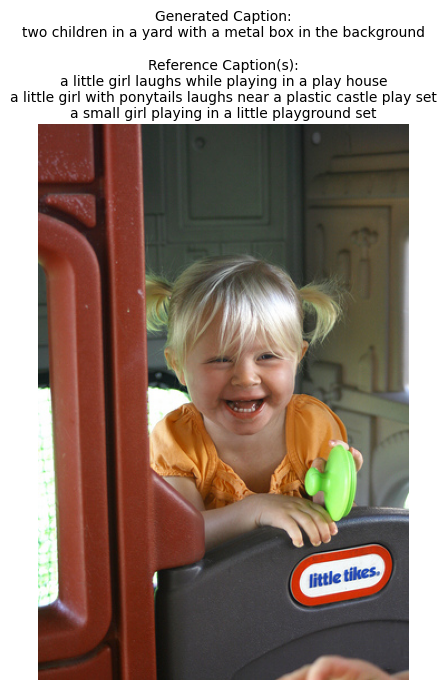

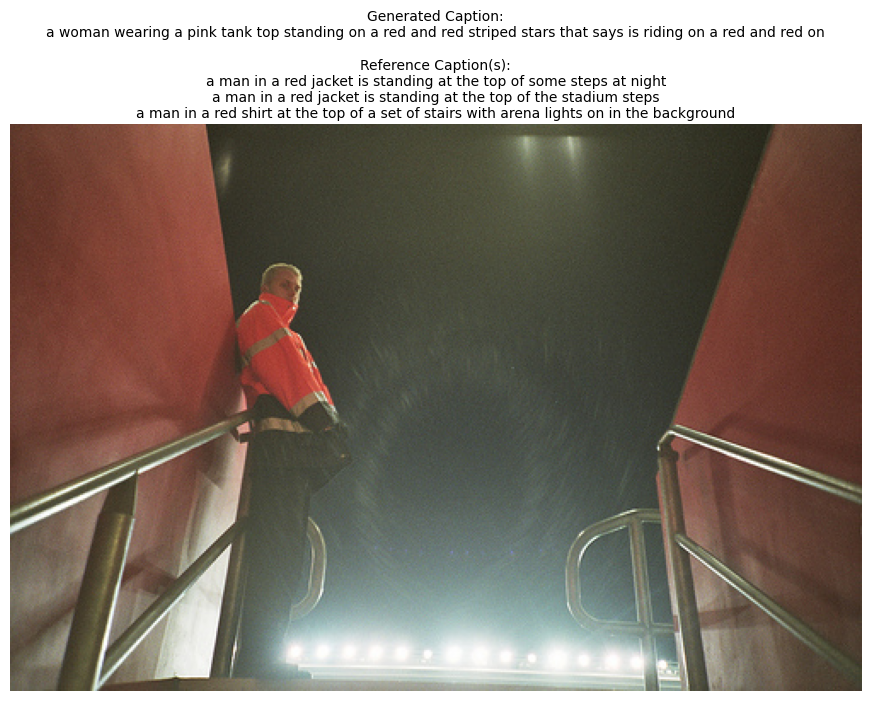

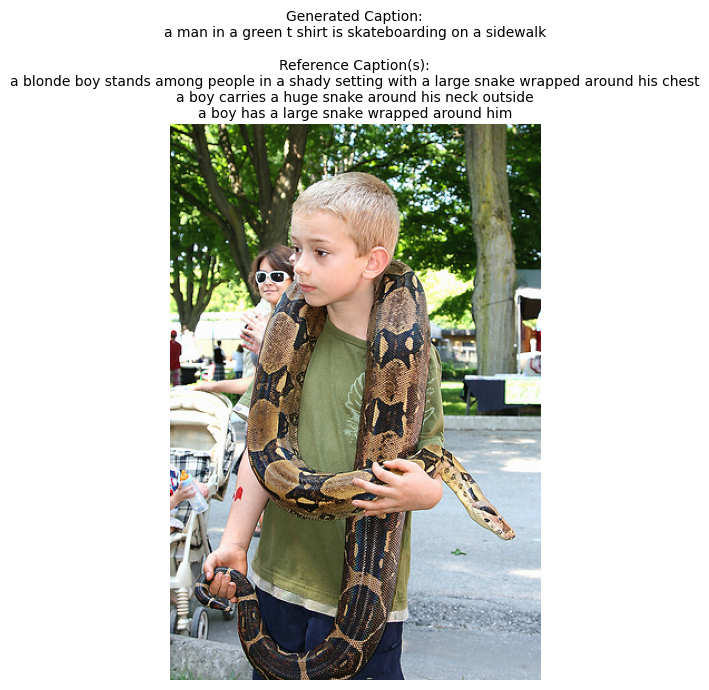


FINAL AVERAGE EVALUATION METRICS
BLEU-1                   : 0.4771 (47.71%)
BLEU-2                   : 0.2851 (28.51%)
BLEU-3                   : 0.1650 (16.50%)
BLEU-4                   : 0.1063 (10.63%)
METEOR                   : 0.3295 (32.95%)
ROUGE-L                  : 0.3637 (36.37%)
Word-level Accuracy      : 0.2798 (27.98%)
Exact Match Accuracy     : 0.0019 (0.19%)
Precision                : 0.4063 (40.63%)
Recall                   : 0.4045 (40.45%)
F1-score                 : 0.3903 (39.03%)


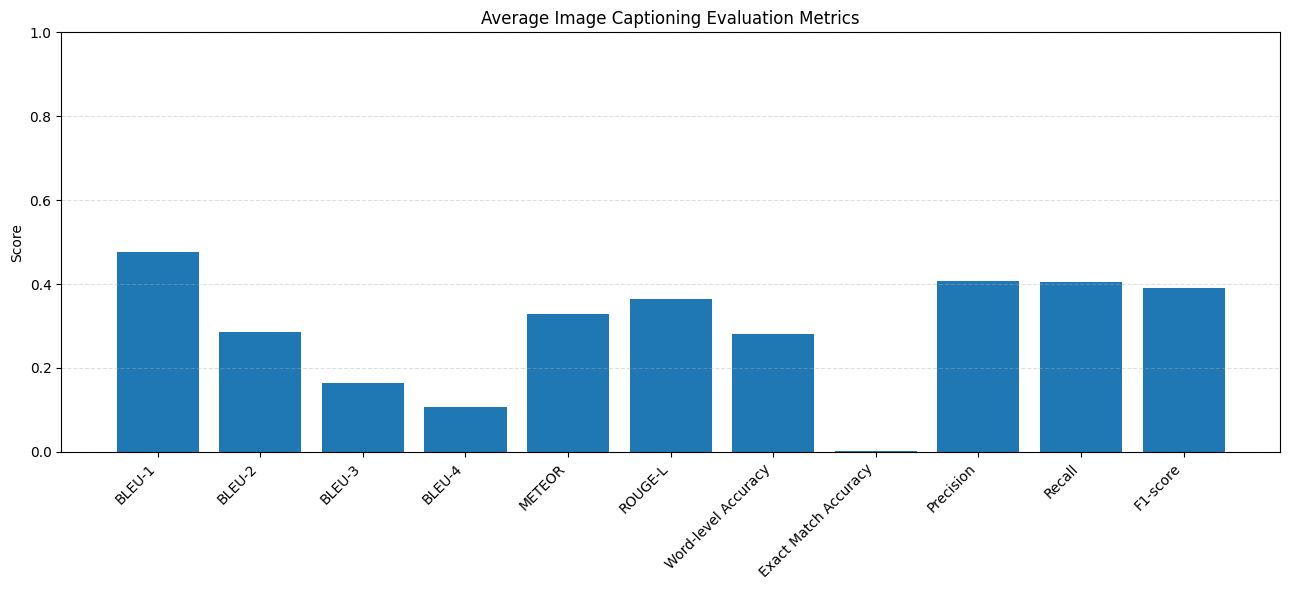

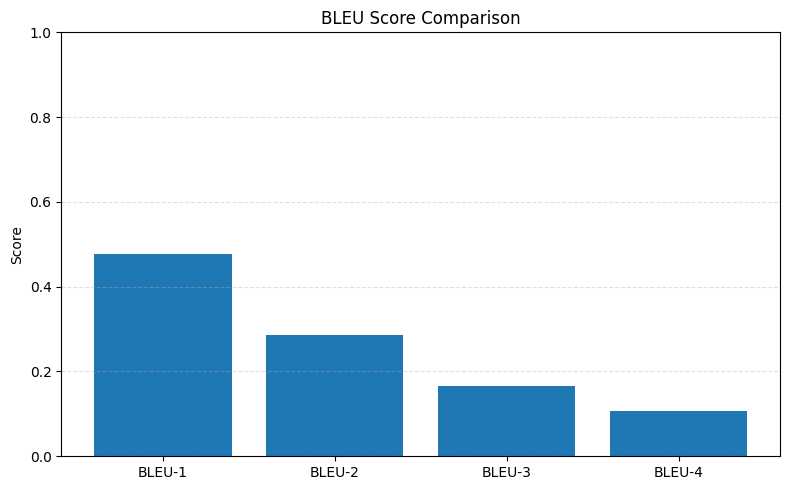

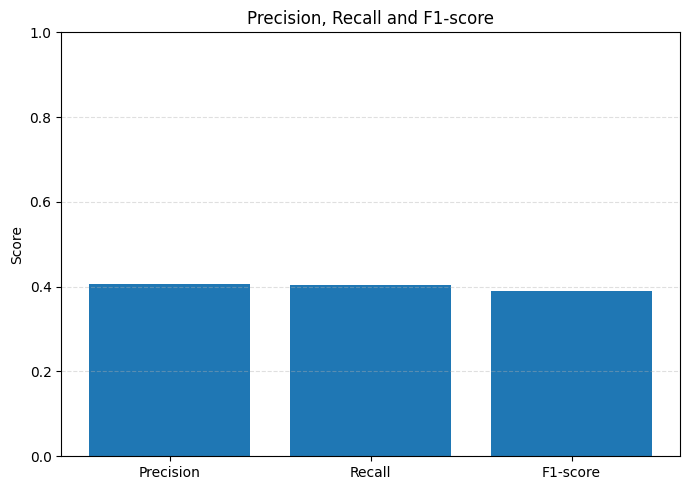

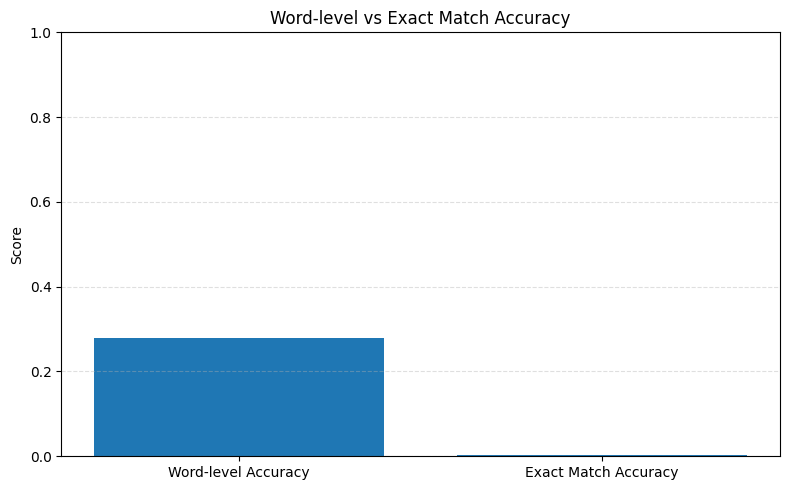


Results saved to:
C:\Users\KIIT\Year_One_MT\AI_ASSIGNMENT\flickr8k_caption_evaluation_results.csv

All evaluation steps completed.


In [67]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from collections import Counter, defaultdict
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from nltk.metrics.distance import edit_distance

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

IMAGE_DIR = r"C:\Users\KIIT\Downloads\Flickr8k_Dataset\Flicker8k_Dataset"

if not os.path.isdir(IMAGE_DIR):
    print("WARNING: Image folder not found.")
    print("Current path:", IMAGE_DIR)
    IMAGE_DIR = input("Paste your actual Flickr8k image folder path: ").strip().strip('"')
    if not os.path.isdir(IMAGE_DIR):
        raise FileNotFoundError("Image folder not found. Check the path: " + IMAGE_DIR)

print("Image folder found:", IMAGE_DIR)

start_id = tokenizer.word_index.get("<start>")
end_id = tokenizer.word_index.get("<end>")

if start_id is None:
    start_id = tokenizer.word_index.get("<startseq>")

if end_id is None:
    end_id = tokenizer.word_index.get("<endseq>")

index_word = tokenizer.index_word

def sequence_to_caption(sequence):
    if sequence is None:
        return ""
    if isinstance(sequence, tuple):
        sequence = sequence[0]
    if hasattr(sequence, "numpy"):
        sequence = sequence.numpy()
    if isinstance(sequence, bytes):
        sequence = sequence.decode("utf-8", errors="ignore")
    if isinstance(sequence, str):
        return sequence
    sequence = np.asarray(sequence).reshape(-1).tolist()
    words = []
    for token in sequence:
        try:
            token_id = int(token)
        except (TypeError, ValueError):
            word = str(token).strip()
            if word in ("<start>", "<startseq>"):
                continue
            if word in ("<end>", "<endseq>"):
                break
            if word not in ("<pad>", ""):
                words.append(word)
            continue
        if token_id == 0:
            continue
        if end_id is not None and token_id == end_id:
            break
        if start_id is not None and token_id == start_id:
            continue
        word = index_word.get(token_id)
        if word and word not in ("<start>", "<startseq>", "<end>", "<endseq>", "<pad>"):
            words.append(word)
    return " ".join(words)


def clean_caption(caption):
    text = sequence_to_caption(caption).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return text.split()

def normalize_image_name(image_name):
    if hasattr(image_name, "numpy"):
        image_name = image_name.numpy()
    if isinstance(image_name, bytes):
        image_name = image_name.decode("utf-8", errors="ignore")
    return os.path.basename(str(image_name).strip().strip("'\""))


image_references = defaultdict(list)
duplicate_count = 0

for image_name, caption_entry in zip(img_name_val, cap_val):
    image_key = normalize_image_name(image_name)
    caption_tokens = clean_caption(caption_entry)
    caption_text = " ".join(caption_tokens)
    if not image_key or not caption_text:
        continue
    if caption_text in image_references[image_key]:
        duplicate_count += 1
    else:
        image_references[image_key].append(caption_text)

image_references = {
    image: references
    for image, references in image_references.items()
    if references
}

unique_images = list(image_references.keys())

print("\nTotal validation entries:", len(img_name_val))
print("Unique images with references:", len(unique_images))
print("Duplicate captions removed:", duplicate_count)

if not unique_images:
    raise ValueError("No reference captions found. Check img_name_val and cap_val.")

def resolve_image_path(image_name):
    if os.path.isfile(image_name):
        return image_name
    candidate = os.path.join(
        IMAGE_DIR,
        os.path.basename(image_name)
    )
    if os.path.isfile(candidate):
        return candidate
    raise FileNotFoundError(
        "Image file not found: " + image_name
        + "\nExpected location: " + candidate
    )

def get_predicted_caption(image_path):
    result = evaluate(image_path)
    if isinstance(result, tuple):
        result = result[0]
    return sequence_to_caption(result)

def overlap_scores(reference_tokens, predicted_tokens):
    if not reference_tokens or not predicted_tokens:
        return 0.0, 0.0, 0.0
    reference_counts = Counter(reference_tokens)
    predicted_counts = Counter(predicted_tokens)
    common_words = sum(
        (reference_counts & predicted_counts).values())
    precision = common_words / len(predicted_tokens)
    recall = common_words / len(reference_tokens)
    if precision + recall == 0:
        f1 = 0.0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return precision, recall, f1


def rouge_l_score(reference_tokens, predicted_tokens):
    if not reference_tokens or not predicted_tokens:
        return 0.0
    rows = len(reference_tokens) + 1
    cols = len(predicted_tokens) + 1
    dp = [[0] * cols for _ in range(rows)]
    for i in range(1, rows):
        for j in range(1, cols):
            if reference_tokens[i - 1] == predicted_tokens[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(
                    dp[i - 1][j],
                    dp[i][j - 1])
    lcs = dp[-1][-1]
    precision = lcs / len(predicted_tokens)
    recall = lcs / len(reference_tokens)
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)

def word_accuracy(reference_tokens, predicted_tokens):
    if not reference_tokens and not predicted_tokens:
        return 1.0
    max_length = max(
        len(reference_tokens),len(predicted_tokens))
    if max_length == 0:
        return 1.0
    distance = edit_distance(reference_tokens,predicted_tokens)
    return max(0.0, 1.0 - distance / max_length)
    

smooth = SmoothingFunction().method1
all_results = []

for number, image_name in enumerate(unique_images, start=1):
    image_path = resolve_image_path(image_name)
    predicted_caption = get_predicted_caption(image_path)
    predicted_tokens = clean_caption(predicted_caption)
    reference_texts = image_references[image_name]
    reference_tokens_list = [
        clean_caption(reference)
        for reference in reference_texts]
    reference_tokens_list = [
        reference
        for reference in reference_tokens_list
        if reference]
    if not reference_tokens_list:
        continue
    scored_references = []
    for reference_tokens in reference_tokens_list:
        _, _, reference_f1 = overlap_scores(
            reference_tokens,
            predicted_tokens)
        scored_references.append((reference_f1, reference_tokens))
    _, best_reference = max(scored_references,key=lambda item: item[0])
    precision, recall, f1 = overlap_scores(best_reference,predicted_tokens)
    bleu_scores = []
    for n in range(1, 5):
        weights = tuple(1.0 / n if index < n else 0.0
                        for index in range(4))
        score = sentence_bleu(reference_tokens_list,predicted_tokens,weights=weights,smoothing_function=smooth)
        bleu_scores.append(score)
    try:
        meteor = meteor_score(references=reference_tokens_list,hypothesis=predicted_tokens)
    except Exception as error:
        print("METEOR error for", image_name, ":", error)
        meteor = 0.0
    rouge_l = max(rouge_l_score(reference, predicted_tokens)
                  for reference in reference_tokens_list)
    word_acc = max(word_accuracy(reference, predicted_tokens)
                   for reference in reference_tokens_list)
    predicted_text = " ".join(predicted_tokens)
    exact_match = float(any(predicted_text == " ".join(reference)
                            for reference in reference_tokens_list))
    all_results.append({
        "Image": image_name,
        "Generated Caption": predicted_text,
        "BLEU-1": bleu_scores[0],
        "BLEU-2": bleu_scores[1],
        "BLEU-3": bleu_scores[2],
        "BLEU-4": bleu_scores[3],
        "METEOR": meteor,
        "ROUGE-L": rouge_l,
        "Word-level Accuracy": word_acc,
        "Exact Match Accuracy": exact_match,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1})
    if number % 100 == 0:
        print("Evaluated", number,"of", len(unique_images), "images")
if not all_results:
    raise ValueError("No images were evaluated. Check evaluate() and dataset variables.")
print("\nEvaluation completed.")
print("Images evaluated:", len(all_results))
print("\nSAMPLE CAPTION CHECK")

for result in all_results[:5]:
    print("\nImage:", result["Image"])
    print("Generated:", repr(result["Generated Caption"]))
    print("References:")
    for reference in image_references[result["Image"]]:
        print(" -", reference)
    print("Precision:", round(result["Precision"], 4))
    print("Recall:", round(result["Recall"], 4))
    print("F1-score:", round(result["F1-score"], 4))

from PIL import Image
import os
import matplotlib.pyplot as plt
for result in all_results[:5]:
    image_name = result["Image"]
    image_path = resolve_image_path(image_name)

    img = Image.open(image_path).convert("RGB")

    plt.figure(figsize=(10, 7))
    plt.imshow(img)
    plt.axis("off")

    generated_caption = result["Generated Caption"]
    reference_captions = image_references[image_name]

    plt.title(
        "Generated Caption:\n"
        + generated_caption
        + "\n\nReference Caption(s):\n"
        + "\n".join(reference_captions[:3]),
        fontsize=10,
        wrap=True
    )

    plt.tight_layout()
    plt.show()

metric_names = [
    "BLEU-1",
    "BLEU-2",
    "BLEU-3",
    "BLEU-4",
    "METEOR",
    "ROUGE-L",
    "Word-level Accuracy",
    "Exact Match Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

mean_metrics = {}

for metric in metric_names:
    mean_metrics[metric] = float(
        np.mean([
            result[metric]
            for result in all_results]))
print("\n" + "=" * 55)
print("FINAL AVERAGE EVALUATION METRICS")
print("=" * 55)

for metric, value in mean_metrics.items():
    print("{:<25}: {:.4f} ({:.2f}%)".format(metric,value,value * 100))


plt.figure(figsize=(13, 6))
plt.bar(list(mean_metrics.keys()),list(mean_metrics.values()))
plt.title("Average Image Captioning Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


bleu_names = [
    "BLEU-1",
    "BLEU-2",
    "BLEU-3",
    "BLEU-4"]

plt.figure(figsize=(8, 5))
plt.bar(bleu_names,[mean_metrics[name] for name in bleu_names])
plt.title("BLEU Score Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

prf_names = [
    "Precision",
    "Recall",
    "F1-score"]

plt.figure(figsize=(7, 5))
plt.bar(prf_names,[mean_metrics[name] for name in prf_names])
plt.title("Precision, Recall and F1-score")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

accuracy_names = [
    "Word-level Accuracy",
    "Exact Match Accuracy"]

plt.figure(figsize=(8, 5))
plt.bar(accuracy_names,[mean_metrics[name] for name in accuracy_names])
plt.title("Word-level vs Exact Match Accuracy")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

results_df = pd.DataFrame(all_results)

output_file = os.path.abspath("flickr8k_caption_evaluation_results.csv")

results_df.to_csv(output_file, index=False)

print("\nResults saved to:")
print(output_file)
print("\nAll evaluation steps completed.")
